# Ordinal grades and costs: an error of one grade is not an error of four

When the classes are ordered, accuracy treats a wine graded 6 instead of 7 the same as one graded
3 instead of 8. This notebook uses red wine quality scores to show what accuracy hides, how an
ordinal encoding and a cost matrix recover it, and how a cost matrix changes which prediction is
best.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from aggmetrics import IndicatorMatrix, pareto_dominance

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## Data

The red *Vinho Verde* wines of Cortez et al. (2009), from the UCI Machine Learning Repository
(CC BY 4.0): 1599 wines, 11 physicochemical measurements and a sensory quality score. The scores
are ordered and unbalanced. The file is in the repository (`examples/data/`, with its source and
citation in the README next to it) and is fetched from GitHub when the notebook runs elsewhere.

In [3]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/winequality-red.csv"
local = Path("../data/winequality-red.csv")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
wine = pd.read_csv(source, sep=";")

X = wine.drop(columns="quality").to_numpy()
quality = wine["quality"].to_numpy()
y = quality - quality.min()                  # grades 3..8 become classes 0..5
grades = np.arange(quality.min(), quality.max() + 1)
print(pd.Series(np.bincount(y), index=grades, name="wines per grade").to_string())

3     10
4     53
5    681
6    638
7    199
8     18


## A classifier and its accuracy

A random forest, with out-of-fold probabilities from 5-fold cross-validation so that every wine is
predicted by a model that did not see it.

In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
proba = cross_val_predict(RandomForestClassifier(300, random_state=0, n_jobs=-1),
                          X, y, cv=cv, method="predict_proba")
pred = proba.argmax(axis=1)

im = IndicatorMatrix(y, pred, task="multiclass", n_classes=6)
print("accuracy:", round(im.accuracy(), 3))

accuracy: 0.695


An accuracy of 0.70 sounds like three wines in ten are graded wrongly. How wrongly?

In [5]:
distance = np.abs(pred - y)
errors = pd.Series({"right": int((distance == 0).sum()),
                    "one grade off": int((distance == 1).sum()),
                    "two or more off": int((distance >= 2).sum())})
errors.to_frame("wines").assign(share=lambda d: (d.wines / d.wines.sum()).round(3))

,wines,share
right,1112,0.695
one grade off,441,0.276
two or more off,46,0.029


Nine in ten errors are exactly one grade off, and only 46 of the 1599 wines are two or more
grades away. Accuracy cannot tell these apart.

The other thing accuracy hides is *which* grades the model predicts. The classifier almost never
predicts the extremes:

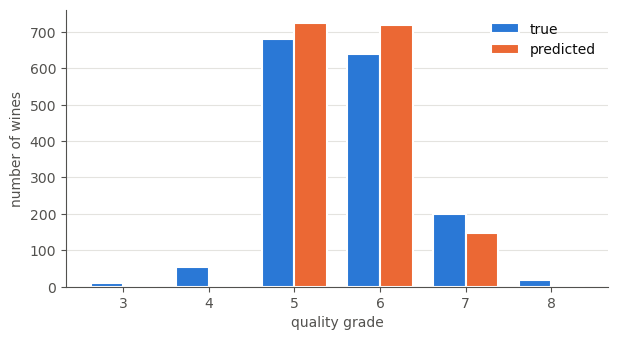

,3,4,5,6,7,8
true,10,53,681,638,199,18
predicted,1,4,725,719,147,3


In [6]:
counts = pd.DataFrame({"true": np.bincount(y, minlength=6),
                       "predicted": np.bincount(pred, minlength=6)}, index=grades)

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(grades))
w = 0.38
ax.bar(x - w / 2, counts["true"], w, color=BLUE, edgecolor="white", linewidth=1.5, label="true")
ax.bar(x + w / 2, counts["predicted"], w, color=ORANGE, edgecolor="white", linewidth=1.5,
       label="predicted")
ax.set_xticks(x)
ax.set_xticklabels(grades)
ax.set_xlabel("quality grade")
ax.set_ylabel("number of wines")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.show()
counts.T

Grades 3, 4 and 8 together account for 81 wines and are predicted 8 times. Recall per grade
shows what that means:

In [7]:
recall = pd.Series(im.parts("recall", "macro"), index=grades, name="recall").round(3)
print(recall.to_string())
print()
print("macro-recall (multiclass):", round(im.compute("recall", "macro"), 3))

3    0.000
4    0.000
5    0.796
6    0.732
7    0.508
8    0.111

macro-recall (multiclass): 0.358


## The ordinal encoding gives credit for near misses

With `task="ordinal"`, the six grades become five cumulative questions: "is the quality above 3?",
"above 4?", and so on up to "above 7?". Each is a binary problem, and a measure under the macro
operator averages over them. A wine graded 6 instead of 7 is wrong on exactly one question,
"above 6?", and right on the other four.

In [8]:
im_ord = IndicatorMatrix(y, pred, task="ordinal", n_classes=6)
thresholds = [f"quality > {g}" for g in grades[:-1]]
per_threshold = pd.Series(im_ord.parts("recall", "macro"), index=thresholds, name="recall").round(3)
print(per_threshold.to_string())
print()
print("macro-recall (ordinal):   ", round(im_ord.compute("recall", "macro"), 3))
print("macro-recall (multiclass):", round(im.compute("recall", "macro"), 3))

quality > 3    0.999
quality > 4    0.998
quality > 5    0.832
quality > 6    0.521
quality > 7    0.111

macro-recall (ordinal):    0.692
macro-recall (multiclass): 0.358


The ordinal macro-recall is 0.69 against 0.36 for the multiclass one, for the same predictions.
The per-threshold values also say where the classifier is weak: it separates the low grades from the
rest almost perfectly, and finds only about one in ten of the wines graded 8 ("above 7").

## Cost matrices

`cost(C)` takes an $m \times m$ matrix where $C_{jk}$ is the cost of predicting class $k$ when the
truth is $j$. The absolute and squared differences give the mean absolute and mean squared error, and
a matrix with 0 on the diagonal and 1 elsewhere is the error rate.

In [9]:
J, K = np.meshgrid(np.arange(6), np.arange(6), indexing="ij")
n = im.n
print("error rate (0/1 cost):", round(im.cost(1 - np.eye(6)) / n, 3), "= 1 - accuracy =", round(1 - im.accuracy(), 3))
print("mean absolute error  :", round(im.cost(np.abs(J - K)) / n, 3), "grades")
print("mean squared error   :", round(im.cost((J - K) ** 2.0) / n, 3))

error rate (0/1 cost): 0.305 = 1 - accuracy = 0.305
mean absolute error  : 0.335 grades
mean squared error   : 0.397


On average the classifier is a third of a grade off. That is a more useful statement of its quality
than "70% accurate", and it comes from the same predictions.

## An asymmetric cost, and the prediction it changes

Suppose a retailer prints the grade on the label. Overrating a wine misleads the customer; underrating
it only loses a little revenue. Say overrating is three times as costly as underrating by the same
number of grades:

In [10]:
C = np.where(K > J, 3.0 * (K - J), (J - K).astype(float))     # true j, predicted k
print(pd.DataFrame(C, index=[f"true {g}" for g in grades], columns=[f"pred {g}" for g in grades]).astype(int))
print()
print("asymmetric cost of the argmax predictions:", round(im.cost(C) / n, 3))
print("wines overrated:", int((pred > y).sum()), "| underrated:", int((pred < y).sum()))

        pred 3  pred 4  pred 5  pred 6  pred 7  pred 8
true 3       0       3       6       9      12      15
true 4       1       0       3       6       9      12
true 5       2       1       0       3       6       9
true 6       3       2       1       0       3       6
true 7       4       3       2       1       0       3
true 8       5       4       3       2       1       0

asymmetric cost of the argmax predictions: 0.669
wines overrated: 238 | underrated: 249


The argmax of the probabilities is the best guess for accuracy. It is not the best guess for this cost.
With probabilities $p_j$ for each grade, the prediction that minimises the *expected* cost is
$\arg\min_k \sum_j p_j C_{jk}$:

In [11]:
pred_cost = (proba @ C).argmin(axis=1)
im_cost = IndicatorMatrix(y, pred_cost, task="multiclass", n_classes=6)

summary = pd.DataFrame({
    name: {
        "accuracy": m.accuracy(),
        "mean absolute error": m.cost(np.abs(J - K)) / n,
        "asymmetric cost": m.cost(C) / n,
        "overrated": int((p > y).sum()),
        "underrated": int((p < y).sum()),
    } for name, m, p in (("argmax", im, pred), ("minimum expected cost", im_cost, pred_cost))
})
summary.round(3)

,argmax,minimum expected cost
accuracy,0.695,0.617
mean absolute error,0.335,0.422
asymmetric cost,0.669,0.559
overrated,238.000,102.000
underrated,249.000,510.000


The cost-minimising predictions are *less* accurate (0.62 against 0.70) and have a *larger* mean
absolute error, yet their asymmetric cost is lower (0.56 against 0.67): they overrate far fewer wines,
at the price of underrating many more. Which one is better depends on the cost you decided on, and
neither is better on every measure:

In [12]:
pareto_dominance(im, im_cost)

'incomparable'

## What to report

- On ordered classes, accuracy alone hides the size of the errors. Report the **mean absolute error**
  (or a cost) next to it, and say how many errors are one grade off.
- The **ordinal encoding** (`task="ordinal"`) gives partial credit to near misses and shows, per
  threshold, where the classifier is weak.
- A **cost matrix** is the most direct statement of the loss. If you can price the errors, put the
  prices in the matrix, and consider choosing predictions from probabilities by minimum expected cost
  instead of by argmax.
- `pareto_dominance` tells you when two prediction rules cannot be ranked without choosing a measure.

Next: *05 Model selection and the CI guard*.